# From FaIR emissions to synthetic North Atlantic tropical cyclones

Follow one September in 2050 from global warming to storm motion. FaIR turns the SSP2-4.5 pathway into a global temperature. A regional emulator draws an ocean–atmosphere background in EOF coordinates and evolves daily winds with a linear inverse model (LIM). Coupled FAST moves and intensifies disturbances in those fields.

Sections 1–4 run paired experiments with LIM and the TC package's native hourly Fourier winds. Sections 5–6 assess how well the emulator reproduces the climate model on which it was trained. Replay the same disturbance with MPI daily winds, LIM and Fourier, then map the eight held-out members' accepted tracks and compare both generators with MPI.

**To run the tutorial**, install the release weights and `requirements-notebook.txt`, then select **Restart Kernel and Run All**. The repository includes the scenario inputs, one MPI reference month, the benchmark's six-hourly tracks and the geographic grids. Figures and tables are written to `runs/fair_to_tc/`. The sample-size settings below control the small live experiment in sections 1–4. The eight-member MPI benchmark has its own fixed design. [Weight installation](../README.md) · [Regional model derivation](../reports/annual_lim_linear_algebra.md) · [MPI benchmark](../reports/mpi2050/README.md)

In [1]:
import os
import sys
from pathlib import Path
for key in ("OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "OMP_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[key] = "1"
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/annual_lim/model.py").is_file())
sys.path[:0] = [str(root / "src"), str(root / "notebooks")]
candidates = [Path(os.environ["ANNUAL_LIM_WEIGHTS"])] if "ANNUAL_LIM_WEIGHTS" in os.environ else []
candidates += [root / "weights", root / "runs/annual_lim/weights", root / "work/weights"]
weights = next((p for p in candidates
                if (p / "09/model.json").is_file()), None)
if weights is None:
    raise FileNotFoundError("Install the v1.0.0 weights using the command in README.md.")
data = root / "notebooks/data"
out = root / "runs/fair_to_tc"
out.mkdir(parents=True, exist_ok=True)

import hashlib
import json
import multiprocessing as mp
import platform
from concurrent.futures import ProcessPoolExecutor
from importlib.metadata import version
from time import perf_counter

%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display
from threadpoolctl import threadpool_limits
from annual_lim.model import MonthlyModel
from annual_lim.sample import event, forcing
from tc_emulator.sampling import fair_years
from tc_emulator.tc_adapter import geography
from tc_benchmark import DAYS, METHODS, MONTH, paired_rates, run_pair

threads = threadpool_limits(limits=1)
seed = 20261119
historical_years = list(range(1985, 2021, 5))
future_year = 2050
future_events = 8
seeds_per_event = 128
workers = max(1, int(os.environ.get("TC_DEMO_WORKERS", "2")))
manifest = json.loads((data / "sources.json").read_text())
for filename, expected in manifest["sha256"].items():
    assert hashlib.sha256((data / filename).read_bytes()).hexdigest() == expected
assert version("fair") == manifest["fair"]["version"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100,
                     "axes.titlelocation": "left", "font.size": 10, "savefig.dpi": 150})
colors = {"Pure LIM": "#007875", "Native Fourier": "#ba532b"}
print(f"{len(historical_years)} historical + {future_events} future panels, "
      f"{seeds_per_event} seeds per panel, {len(METHODS)} drivers, {workers} workers")

8 historical + 8 future panels, 128 seeds per panel, 2 drivers, 3 workers


## Follow the inputs to FAST

The diagram follows one September from annual global temperature to hourly storm tracks. In the fixed-background experiment, all three drivers use the same MPI ocean, atmosphere and candidate disturbances. In the FaIR-only experiment, LIM and Fourier share a generated background, and the evaluation compares their storm distributions with the separate MPI replay. The section numbers on the right refer to this notebook. [Download the three-page workflow](../reports/annual_lim_math_flow.pdf) · [Worked EOF and LIM equations](Annual_Pure_LIM_Tutorial.ipynb#annual-step-5)

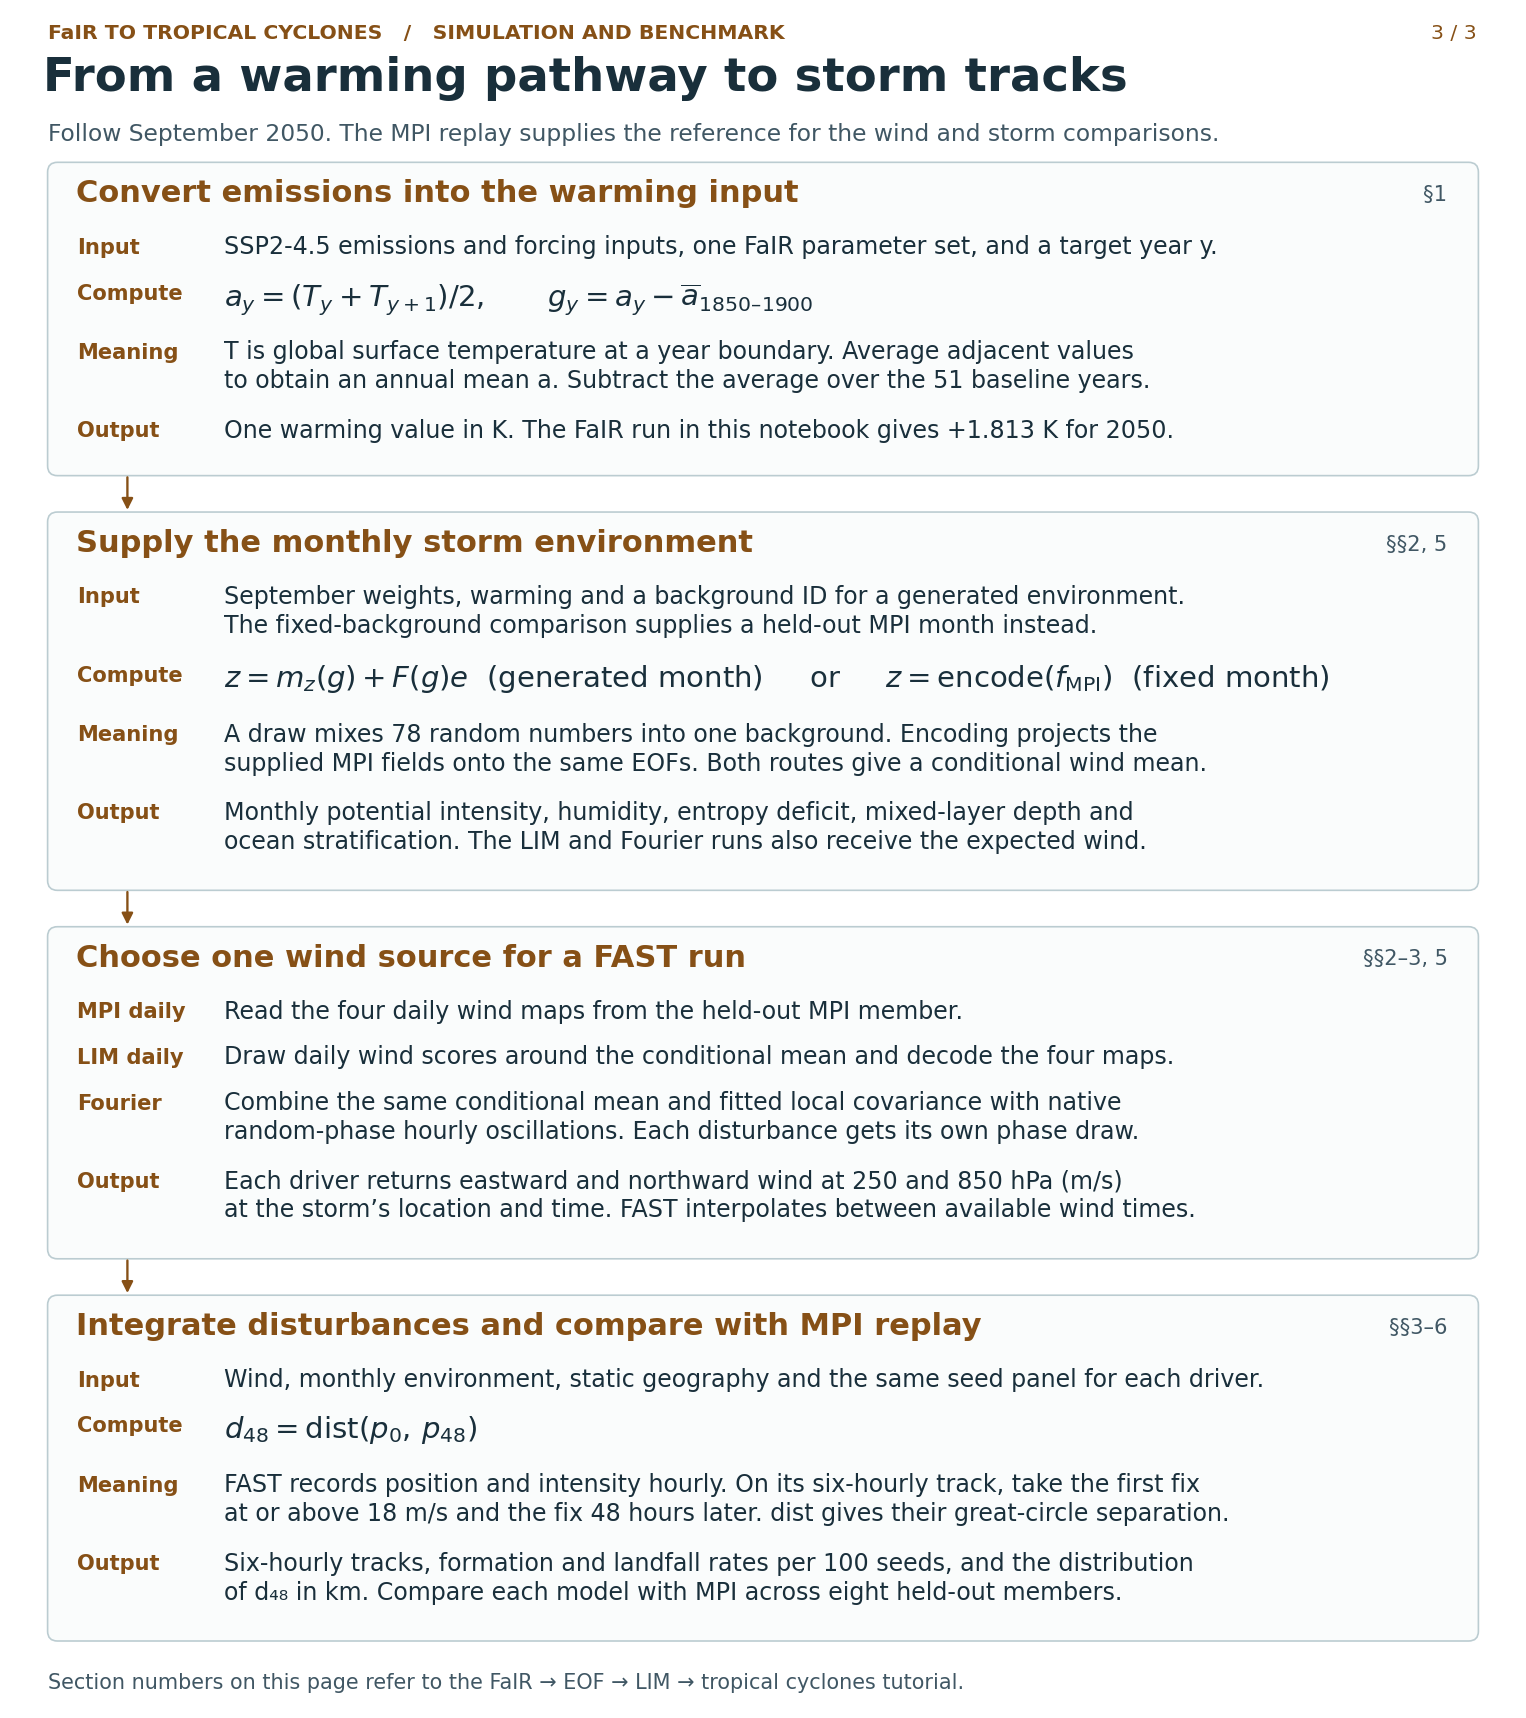

In [2]:
from IPython.display import Image
display(Image(filename=str(root / "reports/annual_lim_tc_flow.png"), width=900,
              alt="FaIR warming selects a September background. MPI daily, LIM daily or Fourier hourly winds then drive identical FAST storm seeds."))

## 1 · Run FaIR on the SSP2-4.5 pathway

The small input archive contains emissions, prescribed concentrations and prescribed radiative forcing in the units and species order expected by FaIR. It can be regenerated from the three original RCMIP tables. It contains no temperature trajectory. Here we run FaIR 2.2.4 with one published parameter configuration (2451, calibration 1.4.1) and turn off stochastic internal temperature noise. This gives one forced global surface air temperature path. The experiment samples regional weather uncertainty separately. [FaIR calibration](https://docs.fairmodel.net/en/v2.2.4/examples/calibrated_constrained_ensemble.html) · [RCMIP 5.1.0](https://doi.org/10.5281/zenodo.4589756) · [Input preparation](prepare_tc_inputs.py)

In [3]:
# FaIR disables its progress bar below, so a Jupyter widget backend is optional.
import warnings
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="IProgress not found.*", module="tqdm.auto")
    from fair import FAIR
from fair.interface import fill, initialise
from fair.io import read_properties

start = perf_counter()
fair = FAIR(ch4_method="Thornhill2021")
config_id = 2451
fair.define_time(1750, 2101, 1)
fair.define_scenarios(["ssp245"])
fair.define_configs([config_id])
fair.define_species(*read_properties(filename=data / "fair_species.csv"))
fair.allocate()
with np.load(data / "rcmip_ssp245.npz", allow_pickle=False) as inputs:
    np.testing.assert_array_equal(inputs["species"], fair.species)
    np.testing.assert_array_equal(inputs["timebounds"], fair.timebounds)
    np.testing.assert_array_equal(inputs["timepoints"], fair.timepoints)
    for name in ("emissions", "concentration", "forcing"):
        fill(getattr(fair, name), inputs[name], scenario="ssp245", config=config_id)
fair.fill_species_configs(data / "fair_species.csv")
fair.override_defaults(data / "fair_2451.csv")
fill(fair.climate_configs["stochastic_run"], False)
params = pd.read_csv(data / "fair_2451.csv", index_col=0).loc[config_id]
for name in ("Solar", "Volcanic"):
    fill(fair.forcing, fair.forcing.sel(specie=name) * params[f"forcing_scale[{name}]"], specie=name)
initialise(fair.concentration, fair.species_configs["baseline_concentration"])
for a in (fair.forcing, fair.temperature, fair.cumulative_emissions,
          fair.airborne_emissions, fair.ocean_heat_content_change):
    initialise(a, 0)
fair.run(progress=False)
surface = fair.temperature.sel(scenario="ssp245", config=config_id, layer=0)
fair_seconds = perf_counter() - start
assert np.isfinite(surface).all()
print(f"Ran {len(fair.timepoints)} annual steps, {len(fair.species)} species, one climate configuration.")

Ran 351 annual steps, 61 species, one climate configuration.


FaIR reports temperature at year boundaries. With linear interpolation between adjacent boundaries, the annual mean for year $y$ is $a_y=[T(y)+T(y+1)]/2$. The regional model uses $g_y=a_y-\frac{1}{51}\sum_{j=1850}^{1900}a_j$. The CSV below exercises the same forcing interface as the command-line sampler. A FaIRGP path with the documented columns can use that interface as well.

2050 global warming = 1.813 K relative to 1850–1900


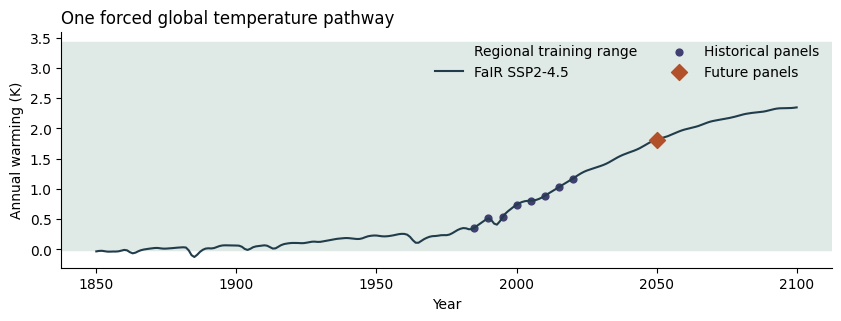

In [4]:
bounds_file = out / "fair_ssp245_timebounds.csv"
pd.DataFrame({"time": fair.timebounds, "forced_temperature": surface.values, "unit": "K",
              "baseline": "1750 initial state", "scenario": "ssp245", "draw_id": str(config_id),
              "temperature_definition": "forced global surface air temperature"}).to_csv(bounds_file, index=False)
warming = fair_years(bounds_file).set_index("year").g
g_future, origin = forcing(None, bounds_file, future_year, "ssp245", str(config_id))
means = (surface.values[:-1] + surface.values[1:]) / 2
years = fair.timebounds[:-1].astype(int)
baseline = means[(years >= 1850) & (years <= 1900)].mean()
np.testing.assert_allclose(warming.loc[years], means - baseline, atol=1e-12)
print(f"{future_year} global warming = {g_future:.3f} K relative to 1850–1900")
model = MonthlyModel(weights, MONTH)
fig, ax = plt.subplots(figsize=(8.3, 3.1), layout="constrained")
ax.axhspan(model.cal.g_min, model.cal.g_max, color="#dfe9e6", label="Regional training range")
ax.plot(warming.loc[1850:], color="#213d4b", label="FaIR SSP2-4.5")
ax.scatter(historical_years, warming.loc[historical_years], color="#413e70", s=24, label="Historical panels")
ax.scatter(future_year, g_future, color="#b25129", s=66, marker="D", label="Future panels", zorder=4)
ax.set(xlabel="Year", ylabel="Annual warming (K)", title="One forced global temperature pathway")
ax.legend(ncol=2, frameon=False)
fig.savefig(out / "warming.png")
plt.show()

## 2 · Decode an EOF background and evolve the wind

The September weights contain regional empirical orthogonal functions (EOFs) fitted to MPI-ESM1-2-LR. The background draw is $z=m(g)+F(g)\epsilon$, where $m(g)$ is the mean vector, $F(g)$ shapes the covariance, and the entries of $\epsilon$ are independent standard normal variates. Decoding converts 78 scores into SST, mixed-layer depth, ocean stratification, pressure and atmospheric profiles. Each map is its training mean plus a weighted sum of EOFs. In panel A, adding one training standard deviation of the first SST score makes the displayed temperature change. Its sign follows the stored EOF convention.

The wind model first samples a stationary Gaussian state with two daily lags, then advances it with a fitted transition matrix and fresh Gaussian innovations. A fitted 5–20 day memory term acts on these states. Adding the background-dependent mean produces 120 daily wind scores. Decoding them gives $u$ and $v$ at 250 and 850 hPa. All disturbances in this LIM event experience the same sequence. [Model equations and estimation](../reports/annual_lim_linear_algebra.md)

In [5]:
demo = event(weights, MONTH, future_year, g_future, DAYS, seed, 0, 0)
z = model.draw_z(g_future, future_year, seed, 0)
np.testing.assert_allclose(z, demo.background_pc)
decoded = model.rep.decode(z[None])
np.testing.assert_allclose(decoded["sst"][0], demo.sst, equal_nan=True)
scores = model.pc_path(g_future, z, DAYS + 3, future_year, seed, 0, 0)
np.testing.assert_allclose(scores, demo.wind_pc)
np.testing.assert_allclose(model.rep.blocks["wind"].inverse(scores), demo.wind)
display(pd.DataFrame([
    {"EOF block": name, "scores": len(block.variance),
     "retained training variance (%)": 100 * block.variance.sum() / block.total_variance}
    for name, block in model.rep.blocks.items()
]).round(1))
print(f"{len(z)} background scores; daily field {demo.wind.shape} (time, component, lat, lon).")
print(f"{DAYS} integration days with wind nodes from day −1 through day {DAYS+1}.")

,EOF block,scores,retained training variance (%)
0,sst,18,89.4
1,ocean,18,56.5
2,psl,14,92.2
3,profiles,28,87.7
4,wind,120,88.0


78 background scores; daily field (18, 4, 36, 58) (time, component, lat, lon).
15 integration days with wind nodes from day −1 through day 16.


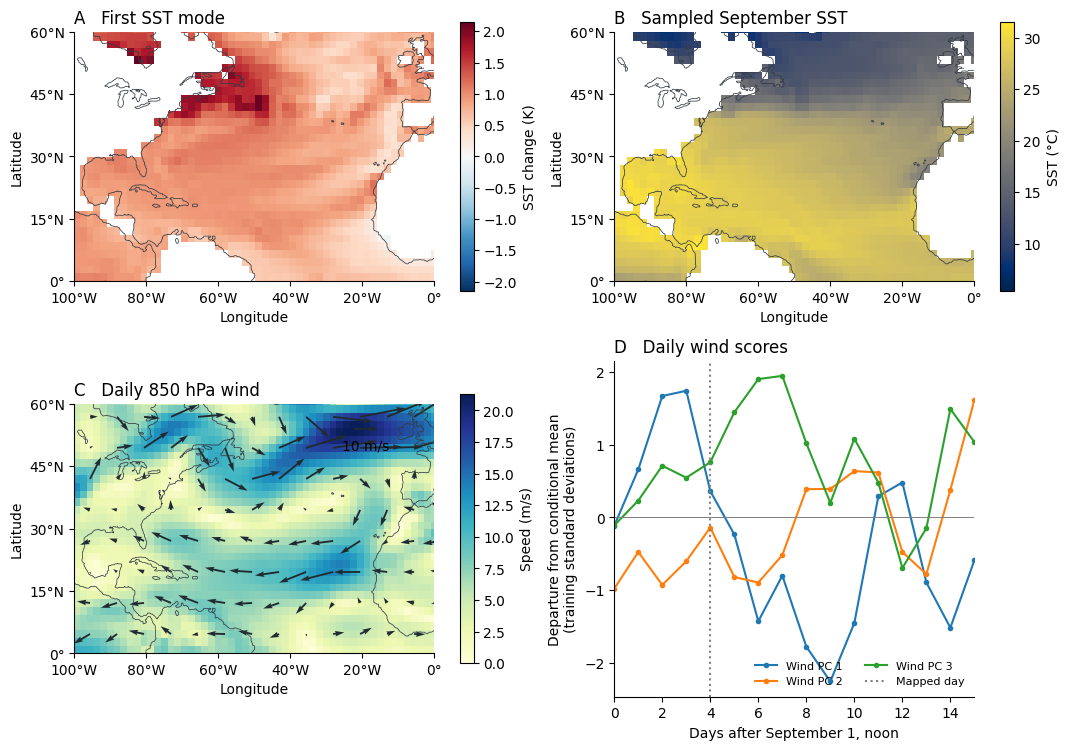

In [6]:
from matplotlib.ticker import FuncFormatter
_, _, _, land, _ = geography()
coast_x = np.linspace(-100, 0, 501)
coast_y = np.linspace(0, 60, 301)
land_fraction = land(coast_x + 360, coast_y).T

def basin_map(ax):
    ax.contour(coast_x, coast_y, land_fraction, levels=[0.5], colors="#333b44", linewidths=0.55)
    ax.set(xlim=(-100, 0), ylim=(0, 60), xlabel="Longitude", ylabel="Latitude")
    ax.set_xticks([-100, -80, -60, -40, -20, 0])
    ax.set_yticks([0, 15, 30, 45, 60])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{abs(x):g}°W" if x else "0°"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}°N" if y else "0°"))
    ax.set_aspect(1 / np.cos(np.deg2rad(30)))

sst = model.rep.blocks["sst"]
score = np.zeros((1, len(sst.variance)))
score[0, 0] = np.sqrt(sst.variance[0])
pattern = (sst.inverse(score) - sst.inverse(0 * score))[0, 0]
x, y = demo.lon.values - 360, demo.lat.values
day = 4     # elapsed time since September 1 at noon
wind = demo.wind.sel(t_seconds=day * 86400)
u, v = (wind.sel(component=k).values for k in ("u850", "v850"))
fig, axs = plt.subplots(2, 2, figsize=(10.6, 7.6), layout="constrained")
peak = np.nanmax(np.abs(pattern))
panels = [(axs[0, 0], pattern, "RdBu_r", -peak, peak, "A   First SST mode", "SST change (K)"),
          (axs[0, 1], demo.sst.values - 273.15, "cividis", None, None, "B   Sampled September SST", "SST (°C)"),
          (axs[1, 0], np.hypot(u, v), "YlGnBu", 0, None, "C   Daily 850 hPa wind", "Speed (m/s)")]
for ax, field, cmap, low, high, title, units in panels:
    im = ax.pcolormesh(x, y, field, cmap=cmap, vmin=low, vmax=high, shading="auto")
    basin_map(ax)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=.8, label=units)
q = axs[1, 0].quiver(x[::4], y[::4], u[::4, ::4], v[::4, ::4], color="#202b31", scale=145)
axs[1, 0].quiverkey(q, .81, .90, 10, "10 m/s", coordinates="axes", labelpos="S")
ax = axs[1, 1]
elapsed = demo.t_seconds.values / 86400
for k in range(3):
    anomaly = (scores[:, k] - demo.conditional_wind_pc.values[k]) / np.sqrt(model.rep.blocks["wind"].variance[k])
    ax.plot(elapsed, anomaly, marker=".", label=f"Wind PC {k+1}")
ax.axhline(0, color="0.5", lw=.7)
ax.axvline(day, color="0.5", ls=":", label="Mapped day")
ax.set(title="D   Daily wind scores", xlabel="Days after September 1, noon",
       ylabel="Departure from conditional mean\n(training standard deviations)", xlim=(0, DAYS))
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.savefig(out / "eof_lim.png")
plt.show()

## 3 · Release the same disturbances into two weather systems

Coupled FAST moves each disturbance with intensity-dependent steering and beta drift. Potential intensity, moisture, vertical wind shear, ocean mixing and land conditions enter the intensity calculation. Random candidate locations are area-uniform in the project's seeding rectangle. FAST screens ocean location, latitude, potential intensity and ventilation. The project counts a TC when the two-day axisymmetric wind reaches 6.5 m/s, its peak reaches 15 m/s and the peak surface wind reaches 18 m/s. A landfall requires an accepted TC and an hourly sea-to-land crossing with surface wind at least 18 m/s. Failed seeds stay in the denominator. [FAST physics and source](https://github.com/linjonathan/tropical_cyclone_risk/tree/a540a1ed86b121f7244557edb691b40561b81939) · [Seeding and classification](../src/tc_emulator/tc_adapter.py)

Each event gets an independent seed panel, one thermodynamic background and one conditional mean wind. Both drivers receive identical seed positions, initial intensities and filter draws. The Fourier driver receives the LIM's exact zero-lag, four-component grid-point covariance at the selected warming. It then uses the native 15-harmonic generator and draws phases separately for each disturbance. The LIM driver shares one spatially varying daily realization across disturbances. The comparison therefore includes spatial coherence, temporal evolution and the choice of sharing weather across seeds. [Covariance calculation and paired integrations](tc_benchmark.py)

The 15-day window begins on September 1. The historical panels sample eight Septembers, spaced five years apart. The future panels sample independent backgrounds and winds at one 2050 warming level. The counts measure outcomes per attempted disturbance. An annual storm count would require a separate calibration of seeding exposure.

In [7]:
# run_pair calls event(...) and tracks(...) for each driver and returns hourly tracks.
historical = [(weights, "Historical", i, y, float(warming.loc[y]), seed, seeds_per_event)
              for i, y in enumerate(historical_years)]
future = [(weights, "Future", i, future_year, g_future, seed, seeds_per_event)
          for i in range(future_events)]
cases = historical + future
started = perf_counter()
if workers == 1:
    results = [run_pair(case) for case in cases]
else:
    with ProcessPoolExecutor(max_workers=workers, mp_context=mp.get_context("spawn")) as pool:
        results = list(pool.map(run_pair, cases))
wall_seconds = perf_counter() - started
paths = xr.concat([p for p, _, _ in results], dim="case", combine_attrs="drop")
attempts = pd.concat([a for _, a, _ in results], ignore_index=True)
times = pd.DataFrame([t for _, _, ts in results for t in ts])
assert len(attempts) == len(cases) * seeds_per_event * len(METHODS)
paired = attempts.set_index(["case", "method", "seed_id"]).sort_index()
seed_columns = ["lon", "lat", "v_init", "filter_draw", "offset_s"]
pd.testing.assert_frame_equal(paired.xs(METHODS[0], level="method")[seed_columns],
                              paired.xs(METHODS[1], level="method")[seed_columns])
assert (attempts.landfall <= attempts.tc).all() and (attempts.tc <= attempts.integrated).all()
assert paths.sizes["elapsed_s"] == 24 * DAYS + 1
for method in METHODS:
    for case_id, group in attempts[attempts.method == method].groupby("case"):
        track = paths.vmax.sel({"method": method, "case": case_id})
        np.testing.assert_array_equal(np.isfinite(track).any("elapsed_s"), group.sort_values("seed_id").integrated)
paths.attrs.update(title="North Atlantic September paired Coupled FAST trajectories",
    month=MONTH, duration_days=DAYS, weather_model=model.meta["id"], seed=seed,
    forcing="FaIR 2.2.4 SSP2-4.5, calibration 1.4.1 configuration 2451",
    event_origin="September 1 at noon in the statistical month",
    outcomes="Join attempts.parquet on case, method and seed_id. Screened seeds have no track.")
for field, unit in {"storm_lon":"degrees_east", "storm_lat":"degrees_north",
                    "vmax":"m s-1", "deep_shear":"m s-1", "elapsed_s":"s", "warming_K":"K"}.items():
    paths[field].attrs["units"] = unit
paths.warming_K.attrs["long_name"] = "annual global temperature relative to 1850–1900"
attempts.to_parquet(out / "attempts.parquet", index=False)
paths.to_netcdf(out / "tracks.nc", encoding={v: {"zlib": True, "complevel": 2} for v in paths.data_vars})
times.to_csv(out / "event_timings.csv", index=False)
print(f"{len(attempts):,} seed attempts across both drivers; {attempts.integrated.sum()} "
      f"passed screening. {paths.sizes['elapsed_s']} possible hourly positions per integration.")

4,096 seed attempts across both drivers; 1632 passed screening. 361 possible hourly positions per integration.


## 4 · Benchmark storm formation, landfall and runtime

The table gives the full count at each stage. Peak wind is the median of the hourly maximum surface winds of **accepted storms** within their 15-day integration windows. A run can stop earlier at dissipation or basin exit. For the paired differences we resample entire event pairs 5,000 times, leaving disturbances that share weather together. The intervals describe sampling variation across these few panels.

Sections 5–6 compare both generators with an MPI daily-wind replay on eight held-out members. To explore sampling in the smaller experiment here, increase `seeds_per_event` to draw more disturbances in the same environments, or `future_events` to draw additional environments. [2050 benchmark design](../reports/mpi2050/design.json)

In [8]:
group = attempts.groupby(["period", "method"], sort=False)
summary = group.agg(events=("case", "nunique"), attempts=("seed_id", "size"),
                    integrated=("integrated", "sum"), TCs=("tc", "sum"), landfalls=("landfall", "sum"))
summary["TC_per_100_attempts"] = 100 * summary.TCs / summary.attempts
summary["landfalls_per_100_attempts"] = 100 * summary.landfalls / summary.attempts
summary["median_peak_wind_ms"] = attempts[attempts.tc].groupby(["period", "method"]).lmi.median()
summary = summary.reindex(pd.MultiIndex.from_product([["Historical", "Future"], METHODS], names=summary.index.names))
summary.to_csv(out / "tc_counts.csv")
display(summary.round(2))
deltas = paired_rates(attempts, seed)
deltas.to_csv(out / "paired_differences.csv", index=False)
display(deltas.round(2))
timing = times.groupby("method").seconds.sum().to_frame("summed_track_call_s")
timing["attempts"] = attempts.groupby("method").size()
timing["attempts_per_solver_s"] = timing.attempts / timing.summed_track_call_s
display(timing.round(2))
print(f"FaIR setup + climate integration: {fair_seconds:.2f} s. Full paired panel wall time: {wall_seconds:.1f} s "
      f"({workers} processes, one BLAS thread each).")
timing.to_csv(out / "solver_timing.csv")
_ = (out / "run.json").write_text(json.dumps(dict(seed=seed, history_years=historical_years, future_year=future_year,
    future_g_K=g_future, baseline="1850–1900", fair_config=config_id, fair_s=fair_seconds, panel_wall_s=wall_seconds,
    weather_model=model.meta["id"], period_days=DAYS, seeds_per_event=seeds_per_event,
    future_events=future_events, workers=workers, cpu_arch=platform.machine(), python=platform.python_version(),
    packages={k:version(k) for k in ("fair", "numpy", "scipy", "pandas", "xarray", "torch")}), indent=2) + "\n")

events  attempts  integrated  TCs  landfalls  \
period     method                                                         
Historical Pure LIM             8      1024         420   27         18   
           Native Fourier       8      1024         414   31         23   
Future     Pure LIM             8      1024         409   32         29   
           Native Fourier       8      1024         389   22         16   

                           TC_per_100_attempts  landfalls_per_100_attempts  \
period     method                                                            
Historical Pure LIM                       2.64                        1.76   
           Native Fourier                 3.03                        2.25   
Future     Pure LIM                       3.12                        2.83   
           Native Fourier                 2.15                        1.56   

                           median_peak_wind_ms  
period     method                               
Historical Pure LIM                      38.54  
           Native Fourier                35.02  
Future     Pure LIM                      37.54  
           Native Fourier                35.38

,period,outcome,paired_events,lim_minus_fourier_pp,event_boot_low_pp,event_boot_high_pp
0,Historical,tc,8,-0.39,-1.76,1.66
1,Historical,landfall,8,-0.49,-2.05,1.76
2,Future,tc,8,0.98,-0.29,2.25
3,Future,landfall,8,1.27,0.20,2.34


,summed_track_call_s,attempts,attempts_per_solver_s
method,,,
Native Fourier,31.92,2048,64.16
Pure LIM,21.98,2048,93.18


FaIR setup + climate integration: 1.37 s. Full paired panel wall time: 24.1 s (3 processes, one BLAS thread each).


Solver seconds sum time inside the track calls across workers and include screening, integration, and recording hourly diagnostics. They exclude background generation and construction of the Fourier provider. Panel wall time also includes those operations and process startup. Each driver can integrate a different number of disturbances, which affects throughput.

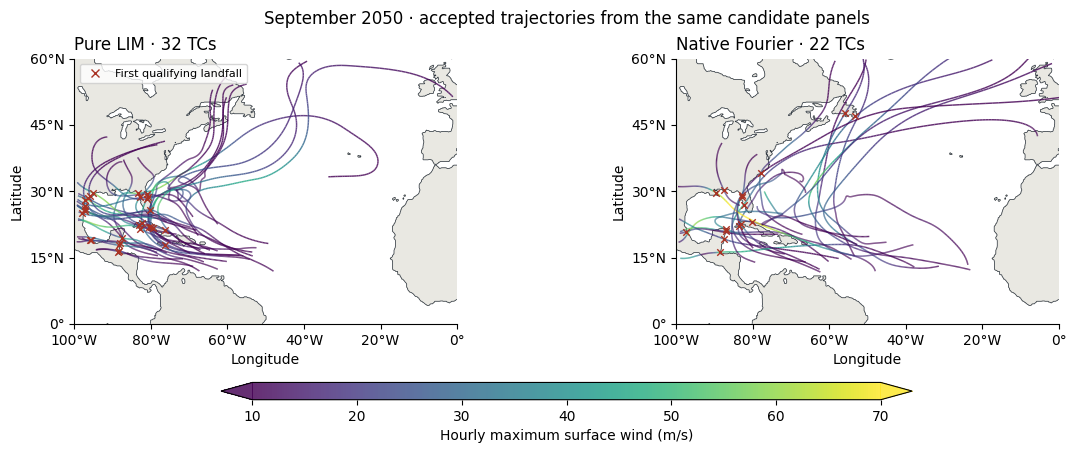

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
norm = Normalize(10, 70, clip=True)
for ax, method in zip(axs, METHODS):
    ax.contourf(coast_x, coast_y, land_fraction, levels=[.5, 1.1], colors=["#e9e8e2"])
    basin_map(ax)
    subset = attempts[(attempts.period == "Future") & (attempts.method == method) & attempts.tc]
    segments, speeds = [], []
    for row in subset.itertuples(index=False):
        t = paths.sel({"case": row.case, "method": method, "seed_id": row.seed_id})
        ok = np.isfinite(t.vmax.values)
        xy = np.column_stack((t.storm_lon.values[ok] - 360, t.storm_lat.values[ok]))
        segments.extend(np.stack((xy[:-1], xy[1:]), axis=1))
        speeds.extend((t.vmax.values[ok][:-1] + t.vmax.values[ok][1:]) / 2)
    lines = LineCollection(segments, cmap="viridis", norm=norm, linewidths=1.05, alpha=.82)
    lines.set_array(np.asarray(speeds))
    ax.add_collection(lines)
    hits = subset[subset.landfall]
    ax.scatter(hits.landfall_lon - 360, hits.landfall_lat, marker="x", s=22,
               color="#a93324", linewidth=1, zorder=4)
    ax.set_title(f"{method} · {len(subset)} TCs")
fig.suptitle(f"September {future_year} · accepted trajectories from the same candidate panels")
fig.colorbar(lines, ax=axs, location="bottom", shrink=.58, aspect=40, label="Hourly maximum surface wind (m/s)",
             extend="both")
axs[0].legend(handles=[Line2D([], [], linestyle="", marker="x", color="#a93324",
                              label="First qualifying landfall")], loc="upper left", fontsize=8)
fig.savefig(out / "tc_tracks.png")
plt.show()

An individual trajectory helps explain why switching the weather driver changes the counts. Take the first future case and seed ID (in numerical order) that qualifies as a TC with both drivers. Both tracks begin with the same initial location and intensity. As their environmental winds and positions diverge, the vertical shear along each path can also change. The monthly ocean background is fixed in both runs.

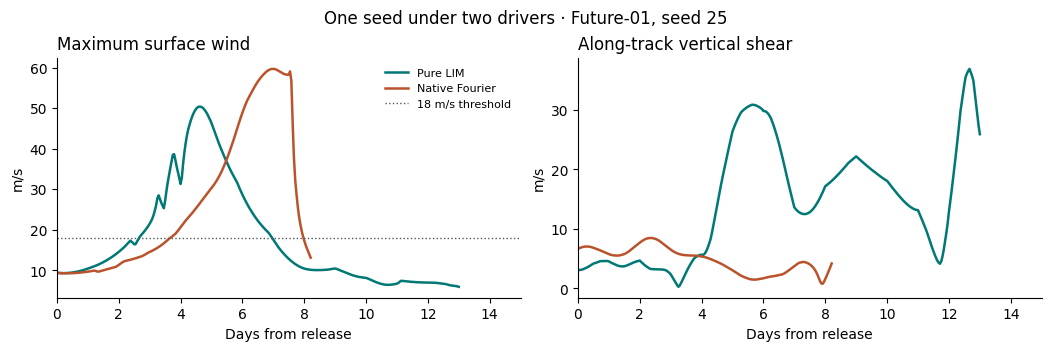

In [10]:
future_rows = attempts[attempts.period == "Future"]
qualified = future_rows.pivot(index=["case", "seed_id"], columns="method", values="tc").all(axis=1)
integrated = future_rows.pivot(index=["case", "seed_id"], columns="method", values="integrated").all(axis=1)
pairs = qualified[qualified].index if qualified.any() else integrated[integrated].index
if len(pairs):
    case_id, seed_id = pairs[0]
    fig, axs = plt.subplots(1, 2, figsize=(10.4, 3.4), layout="constrained")
    for method in METHODS:
        tr = paths.sel({"case": case_id, "method": method, "seed_id": seed_id})
        for ax, var, title in zip(axs, ["vmax", "deep_shear"], ["Maximum surface wind", "Along-track vertical shear"]):
            ax.plot(tr.elapsed_s / 86400, tr[var], color=colors[method], label=method, linewidth=1.8)
            ax.set(title=title, xlabel="Days from release", ylabel="m/s", xlim=(0, DAYS))
    axs[0].axhline(18, ls=":", color="#51575b", lw=1, label="18 m/s threshold")
    axs[0].legend(frameon=False, fontsize=8)
    fig.suptitle(f"One seed under two drivers · {case_id}, seed {seed_id}")
    fig.savefig(out / "storm_evolution.png")
    plt.show()
else:
    print("No future seed integrated under both drivers in this panel.")

## 5 · Replay September 2050 with MPI daily winds

What would the same disturbance do in weather actually produced by the climate model? The reference run feeds MPI-ESM1-2-LR's daily eastward and northward winds at 250 and 850 hPa into FAST. The other two runs use the same MPI monthly ocean and atmospheric fields and switch the wind generator. All three start from the same location and intensity and use the same screening draw. The tracks are synthetic FAST storms in the SSP2-4.5 model climate. [MPI-M SSP2-4.5 data, Wieners et al.](https://doi.org/10.22033/ESGF/CMIP6.6693) · [Input files and preprocessing](../reports/mpi2050/README.md)

For a reproducible example, take the first held-out member in the published split. Within that member, take the first weather draw, start date and seed ID in ascending order for which all three archived storms have a complete 48-hour window. The selection uses availability alone. Each driver's window starts at its own first six-hourly fix with wind of at least 18 m/s.

In [11]:
from benchmark_mpi2050 import (DESIGN, FOURIER, LIM, MPI, SEED as mpi_seed,
                               fourier_inputs, sampled_window, seed_panel)
from tc_benchmark import aligned_window
from tc_emulator.fourier_weather import NativeFourierWind, WindStatistics
from tc_emulator.tc_adapter import replay_event, tracks

mpi_report = root / "reports/mpi2050"
mpi_out = out / "mpi2050"
mpi_out.mkdir(exist_ok=True)
drivers = [MPI, LIM, FOURIER]
colors[MPI] = "#384757"
fixed_bg, fair_only = "MPI background", "FaIR warming only"
storm_key = ["protocol", "method", "member", "draw", "origin", "seed_id"]

mpi_year, mpi_month, duration = DESIGN["year"], DESIGN["month"], DESIGN["event_days"]
member = json.loads((root / "configs/annual_lim/members.json").read_text())["test"][0]
mpi_g = json.loads((mpi_report / "forcing.json").read_text())["warming_K"]
reference_file = data / "mpi_ssp245_r9_2050_09.nc"
expected = json.loads((mpi_report / "reproducibility.json").read_text())["reference_inputs"][member]
assert hashlib.sha256(reference_file.read_bytes()).hexdigest() == expected
with xr.open_dataset(reference_file, decode_times=False) as ds:
    mpi_fields = ds.load()
assert (mpi_fields.attrs["member"], mpi_fields.attrs["experiment"],
        mpi_fields.attrs["year"], mpi_fields.attrs["month"]) == (member, "ssp245", mpi_year, mpi_month)

mpi_attempts = pd.read_parquet(mpi_report / "attempts.parquet")
same_background = mpi_attempts[mpi_attempts.protocol.isin(["Reference", fixed_bg]) &
                               mpi_attempts.method.isin(drivers)]
available = (same_background.loc[same_background.member.eq(member) & same_background.tc]
             .pivot(index=["draw", "origin", "seed_id"], columns="method", values="displacement_48h_km")
             .reindex(columns=drivers).dropna().sort_index())
draw, origin, example_id = map(int, available.index[0])
seeds = seed_panel(member, draw, origin)
one_seed = seeds.loc[seeds.seed_id.eq(example_id)]
print(f"{member}, September {origin}, {mpi_year}, noon UTC · draw {draw}, seed {example_id}")
print(f"MPI warming {mpi_g:+.3f} K · FaIR warming for the same year {warming.loc[mpi_year]:+.3f} K")

r9i1p1f1, September 5, 2050, noon UTC · draw 1, seed 74
MPI warming +1.799 K · FaIR warming for the same year +1.813 K


In [12]:
# One generator gets MPI's daily wind directly. LIM and Fourier share the predicted
# wind mean and pointwise covariance specification conditional on MPI's monthly background.
mpi_env = replay_event(mpi_fields, duration, origin_day=origin)
ident = f"{member}/{draw}"
sampled_month = event(weights, mpi_month, mpi_year, mpi_g, 30, mpi_seed, ident, draw, observed=mpi_fields)
lim_env = sampled_window(sampled_month, origin, duration)
mpi_model, unit_cov = fourier_inputs(weights)
mean_wind = mpi_model.rep.blocks["wind"].inverse(sampled_month.conditional_wind_pc.values[None])[0]
fourier_stats = WindStatistics(mean_wind, unit_cov * mpi_model.cal.amplitude(mpi_g)**2)
fourier_driver = NativeFourierWind(fourier_stats, mpi_fields.lon.values, mpi_fields.lat.values,
                                   mpi_seed, ("SSP245", mpi_year, member), draw,
                                   independent_storms=True, origin_day=origin)
np.testing.assert_array_equal(mpi_env.vpot, lim_env.vpot)

live_paths, live_windows, example_rows = {}, {}, []
for driver, environment, wind_driver in [(MPI, mpi_env, None), (LIM, lim_env, None),
                                          (FOURIER, lim_env, fourier_driver)]:
    hourly, outcome = tracks(environment, one_seed, duration, wind_provider=wind_driver)
    t = hourly.sel(seed_id=example_id).isel(elapsed_s=slice(None, None, 6))
    hours = t.elapsed_s.values / 3600
    v = t.vmax.values
    window = aligned_window(t.storm_lon.values, t.storm_lat.values, v, hours, np.isfinite(v))
    live_paths[driver], live_windows[driver] = t, window
    start_h, distance = (hours[window[0]], window[2]) if window is not None else (np.nan, np.nan)
    example_rows.append([driver, outcome.tc.item(), start_h, distance,
                         available.loc[(draw, origin, example_id), driver]])
display(pd.DataFrame(example_rows, columns=["Wind driver", "Accepted TC", "Window starts (h)",
                                            "Live displacement (km)", "Archived displacement (km)"])
        .set_index("Wind driver").round(1))

,Accepted TC,Window starts (h),Live displacement (km),Archived displacement (km)
Wind driver,,,,
MPI daily,True,144.0,999.0,999.0
Pure LIM,True,66.0,1372.4,1372.4
Native Fourier,True,270.0,1449.5,1449.5


### A common release and the full track ensemble

Each basin map below shows the six-hourly positions of **every accepted storm** under that driver, from seed release until the end of integration. The panels use the same eight held-out members, September 5 and 14 starts, four seed panels per member and start, and 256 proposed disturbances per panel. A driver can turn a different subset of those 16,384 disturbances into storms.

The enlarged map follows the common seed just integrated. The dotted section connects the release to the first qualifying fix. The solid section covers the following 48 hours. A circle marks the start of that window and a square marks its end. The wind that drives FAST changes the timing as well as the direction of travel. [Stored six-hourly positions](../reports/mpi2050/tc_tracks_6h.parquet)

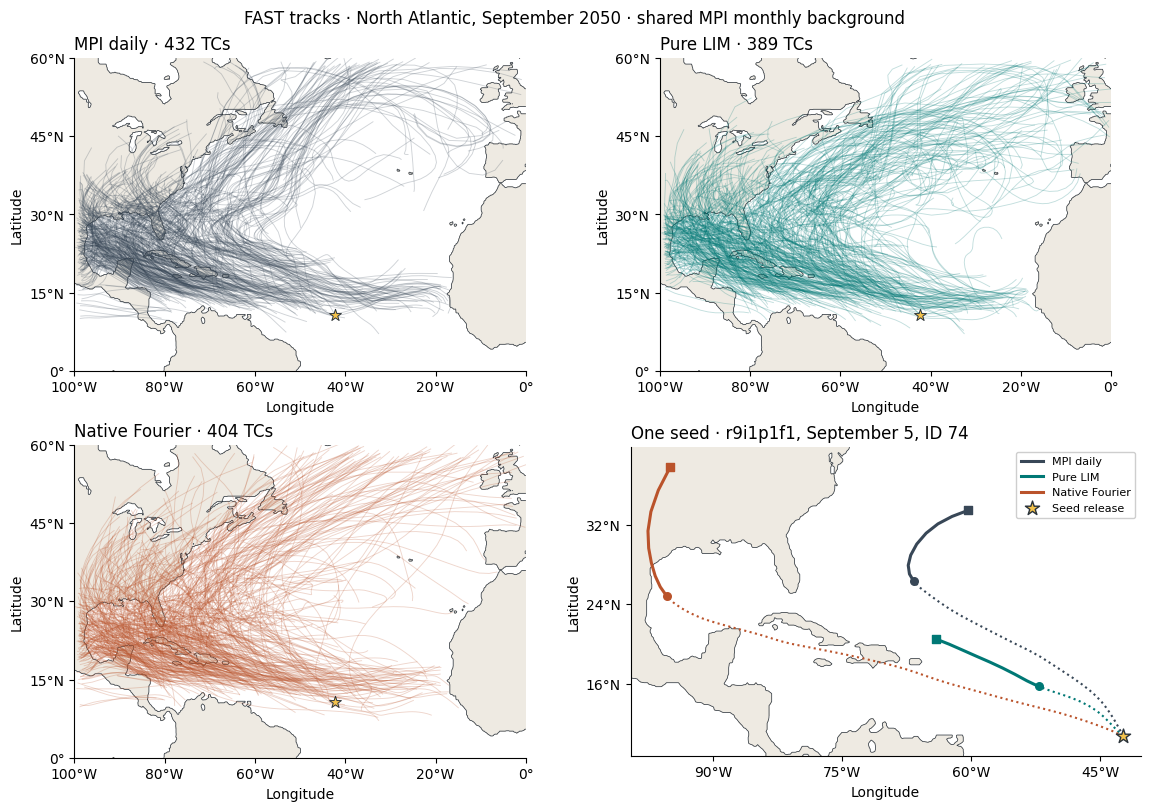

In [13]:
from matplotlib.ticker import MaxNLocator

fixes = pd.read_parquet(mpi_report / "tc_tracks_6h.parquet").sort_values(storm_key + ["elapsed_h"])
assert not fixes.duplicated(storm_key + ["elapsed_h"]).any()
assert np.isfinite(fixes[["lon_e", "lat_n", "vmax_ms"]].to_numpy()).all()
accepted = mpi_attempts.loc[mpi_attempts.tc].set_index(storm_key).sort_index()
track_ids = pd.MultiIndex.from_frame(fixes[storm_key].drop_duplicates())
pd.testing.assert_index_equal(track_ids, accepted.index)

fig, axs = plt.subplots(2, 2, figsize=(11.4, 8.0), layout="constrained")
for ax, driver in zip(axs.flat[:3], drivers):
    case_protocol = "Reference" if driver == MPI else fixed_bg
    group = fixes[fixes.protocol.eq(case_protocol) & fixes.method.eq(driver)]
    segments = [np.column_stack((track.lon_e.to_numpy() - 360, track.lat_n))
                for _, track in group.groupby(["member", "draw", "origin", "seed_id"], sort=False)]
    ax.contourf(coast_x, coast_y, land_fraction, levels=[.5, 1.1], colors=["#eeeae2"])
    basin_map(ax)
    ax.add_collection(LineCollection(segments, colors=colors[driver], linewidths=.65, alpha=.24))
    ax.scatter(one_seed.lon - 360, one_seed.lat, marker="*", s=80, c="#f4c34c",
               edgecolors="#29323a", linewidths=.7, zorder=4)
    ax.set_title(f"{driver} · {len(segments)} TCs")

ax = axs[1, 1]
ax.contourf(coast_x, coast_y, land_fraction, levels=[.5, 1.1], colors=["#eeeae2"])
basin_map(ax)
x0, y0 = float(one_seed.lon.iloc[0] - 360), float(one_seed.lat.iloc[0])
shown = [np.array([[x0, y0]])]
for driver in drivers:
    t, window = live_paths[driver], live_windows[driver]
    xy = np.column_stack((t.storm_lon.values - 360, t.storm_lat.values))
    if window is None:
        xy = xy[np.isfinite(xy).all(axis=1)]
        ax.plot(*xy.T, color=colors[driver], ls=":", label=f"{driver} (incomplete)")
    else:
        begin = window[0]
        xy = xy[:begin + 9]
        ax.plot(*xy[:begin + 1].T, color=colors[driver], ls=":", lw=1.5)
        ax.plot(*xy[begin:].T, color=colors[driver], lw=2.2, label=driver)
        ax.scatter(*xy[begin], color=colors[driver], s=30, marker="o", zorder=4)
        ax.scatter(*xy[-1], color=colors[driver], s=30, marker="s", zorder=4)
    shown.append(xy)
ax.scatter(x0, y0, marker="*", s=115, c="#f4c34c", edgecolors="#29323a", zorder=5, label="Seed release")
extent = np.concatenate(shown)
ax.set(xlim=(extent[:, 0].min()-2, extent[:, 0].max()+2), ylim=(extent[:, 1].min()-2, extent[:, 1].max()+2))
ax.xaxis.set_major_locator(MaxNLocator(5))
ax.yaxis.set_major_locator(MaxNLocator(5))
ax.set_title(f"One seed · {member}, September {origin}, ID {example_id}")
ax.legend(frameon=True, framealpha=.95, fontsize=8, loc="best")
fig.suptitle("FAST tracks · North Atlantic, September 2050 · shared MPI monthly background")
fig.savefig(mpi_out / "mpi_track_maps.png")
plt.show()

## 6 · Measure skill against the MPI-driven storms

The same seed can take quite different paths even when the ensemble distribution is right. For every accepted storm, use the position at the first six-hourly wind of at least 18 m/s and its position eight fixes later. Their great-circle separation is the **48-hour displacement**. All eligible storms from each method enter its distribution. Formation and landfall rates use every proposed seed in the denominator, including those that never integrate.

The first panel holds the MPI monthly background fixed. The second supplies only FaIR warming to the emulator, which generates a new monthly background shared by LIM and Fourier. Both panels use the same MPI reference. For distance $x$, the vertical coordinate $F(x)$ is the fraction of storms with displacement at most $x$. The Wasserstein distance $W_1=\int |F_{\mathrm{driver}}(x)-F_{\mathrm{MPI}}(x)|\,dx$ measures the area between the curves, in kilometres. A smaller value means closer agreement across the distribution.

In [14]:
# Rebuild the displacement sample from positions. Check every storm, including
# accepted storms that end too early to supply a complete 48-hour window.
measurements = []
for identity, track in fixes.groupby(storm_key, sort=False):
    hours = track.elapsed_h.to_numpy()
    assert hours[0] == 0 and np.all(np.diff(hours) == 6)
    window = aligned_window(track.lon_e.to_numpy(), track.lat_n.to_numpy(), track.vmax_ms.to_numpy(),
                            hours, np.ones(len(track), dtype=bool))
    measurements.append((*identity, window[2] if window is not None else np.nan))
distances = pd.DataFrame(measurements, columns=[*storm_key, "km"]).set_index(storm_key).sort_index()
pd.testing.assert_index_equal(distances.index, accepted.index)
# Allow 5 m for differences in floating-point trigonometry across NumPy builds.
np.testing.assert_allclose(distances.km, accepted.displacement_48h_km, atol=0.005, rtol=0, equal_nan=True)
distances = distances.reset_index()
print(f"{len(fixes):,} six-hourly positions · {len(accepted):,} accepted tracks across all archived main runs")

118,471 six-hourly positions · 3,242 accepted tracks across all archived main runs


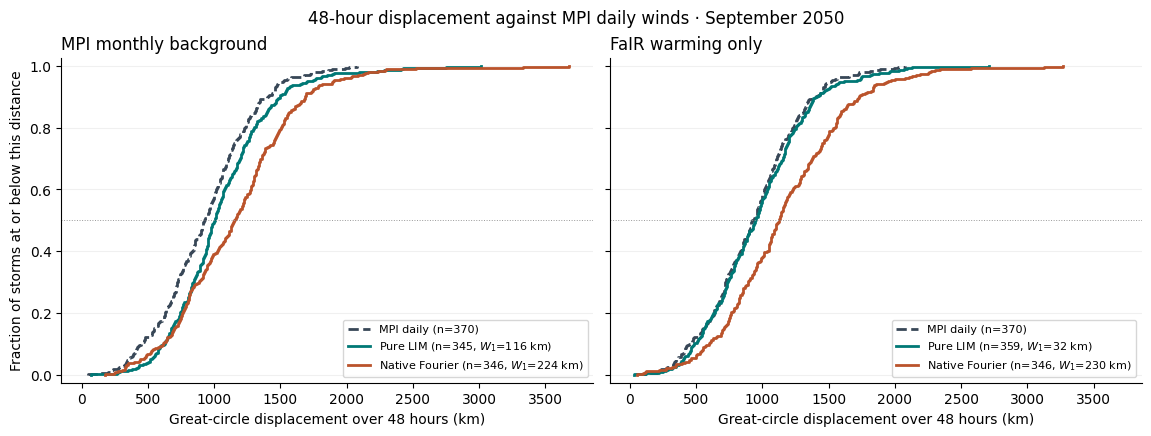

Attempts  TCs  TC landfalls  48 h windows  \
Inputs            Wind driver                                                 
Reference         MPI daily          16384  432           337           370   
MPI background    Pure LIM           16384  389           281           345   
                  Native Fourier     16384  404           313           346   
FaIR warming only Pure LIM           16384  399           283           359   
                  Native Fourier     16384  400           303           346   

                                  Median displacement (km)  W1 to MPI (km)  
Inputs            Wind driver                                               
Reference         MPI daily                          925.6             0.0  
MPI background    Pure LIM                          1007.2           116.0  
                  Native Fourier                    1156.0           224.3  
FaIR warming only Pure LIM                           947.0            31.8  
                  Native Fourier                    1125.2           229.8

In [15]:
from scipy.stats import wasserstein_distance

conditions = {fixed_bg: "MPI monthly background", fair_only: "FaIR warming only"}
reference_km = distances.loc[distances.method.eq(MPI), "km"].dropna().to_numpy()
fig, axs = plt.subplots(1, 2, figsize=(11.4, 4.25), sharex=True, sharey=True, layout="constrained")
table = []
for ax, (condition, label) in zip(axs, conditions.items()):
    for driver in drivers:
        protocol = "Reference" if driver == MPI else condition
        group = mpi_attempts[mpi_attempts.protocol.eq(protocol) & mpi_attempts.method.eq(driver)]
        km = distances.loc[distances.protocol.eq(protocol) & distances.method.eq(driver), "km"].dropna().to_numpy()
        w1 = wasserstein_distance(reference_km, km)
        line_label = f"{driver} (n={len(km)})" if driver == MPI else f"{driver} (n={len(km)}, $W_1$={w1:.0f} km)"
        ax.ecdf(km, color=colors[driver], ls="--" if driver == MPI else "-", lw=2, label=line_label)
        if driver != MPI or condition == fixed_bg:
            table.append([protocol, driver, len(group), int(group.tc.sum()), int(group.landfall.sum()),
                          len(km), np.median(km), w1])
    ax.set(title=label, xlabel="Great-circle displacement over 48 hours (km)", ylim=(-.025, 1.025))
    ax.axhline(.5, lw=.7, color=".6", ls=":")
    ax.grid(axis="y", alpha=.18)
    ax.legend(loc="lower right", frameon=True, fontsize=8)
axs[0].set_ylabel("Fraction of storms at or below this distance")
fig.suptitle("48-hour displacement against MPI daily winds · September 2050")
fig.savefig(mpi_out / "mpi_displacement_cdf.png")
plt.show()

storm_stats = pd.DataFrame(table, columns=["Inputs", "Wind driver", "Attempts", "TCs", "TC landfalls",
                                           "48 h windows", "Median displacement (km)", "W1 to MPI (km)"])
storm_stats.to_csv(mpi_out / "storm_statistics.csv", index=False)
display(storm_stats.set_index(["Inputs", "Wind driver"]).round(1))

### How much of the difference survives resampling?

The wind panel uses $0.2\,\mathbf u_{250}+0.8\,\mathbf u_{850}$ as a fixed steering diagnostic. At each grid point subtract its September mean, average over 1, 5, 10 or 15 days, then calculate the area-weighted mean squared anomaly over both vector components. FAST uses intensity-dependent steering weights when moving an individual storm.

For each of the three storm panels, the dot is **Fourier error minus LIM error**. Positive values favour LIM. The displacement error is $W_1$ in km. The formation and landfall errors are absolute differences from the MPI rate per 100 proposed seeds. To draw the 95% intervals, resample the eight **whole MPI members** 5,000 times. Both generators keep the same members, dates and seed panels on every draw. An interval that spans zero leaves the ranking unresolved for this experiment. [Paired scoring implementation](score_mpi2050.py)

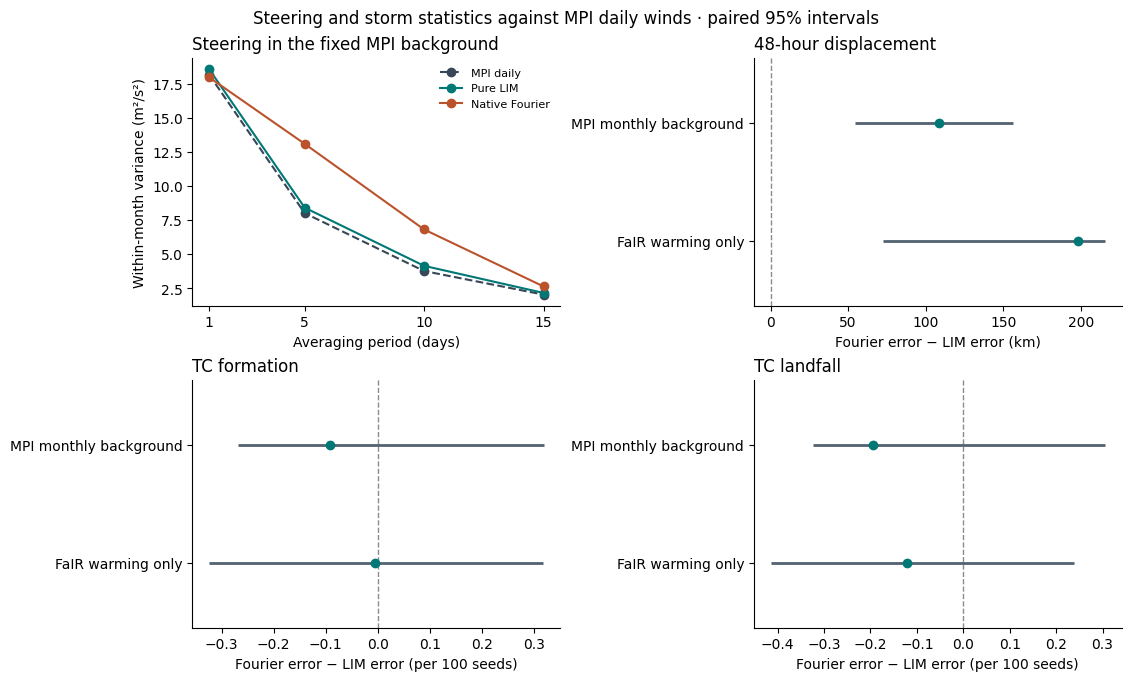

In [16]:
from score_mpi2050 import summarize

paired_scores, _, _ = summarize(mpi_report)  # Recompute rates, W1 distances and paired intervals.
scores_native = paired_scores[paired_scores.comparator.eq(FOURIER)].set_index(["protocol", "metric"])
for row in storm_stats.itertuples(index=False, name=None):
    protocol, driver, *_, w1 = row
    if driver != MPI:
        col = "lim_error" if driver == LIM else "fourier_error"
        np.testing.assert_allclose(w1, scores_native.loc[(protocol, "displacement_48h_km"), col], atol=0.005, rtol=0)

fig, axs = plt.subplots(2, 2, figsize=(11.2, 6.7), layout="constrained")
ax = axs[0, 0]
days = [1, 5, 10, 15]
wind = scores_native.loc[fixed_bg].loc[[f"steering_{d}d" for d in days]]
for driver, col in zip(drivers, ["reference", "lim", "fourier"]):
    ax.plot(days, wind[col], marker="o", color=colors[driver], ls="--" if driver == MPI else "-", label=driver)
ax.set(title="Steering in the fixed MPI background", xlabel="Averaging period (days)",
       ylabel="Within-month variance (m²/s²)", xticks=days)
ax.legend(frameon=False, fontsize=8)

metrics = [("displacement_48h_km", "48-hour displacement", "km"),
           ("tc_per_100", "TC formation", "per 100 seeds"),
           ("landfall_per_100", "TC landfall", "per 100 seeds")]
for ax, (metric, title, unit) in zip(axs.flat[1:], metrics):
    ax.axvline(0, color=".55", ls="--", lw=1)
    for i, condition in enumerate(conditions):
        r = scores_native.loc[(condition, metric)]
        ax.hlines(i, r.paired_low, r.paired_high, color="#526270", lw=2)
        ax.plot(r.advantage, i, "o", color=colors[LIM], ms=6)
    ax.set(title=title, xlabel=f"Fourier error − LIM error ({unit})",
           yticks=[0, 1], yticklabels=list(conditions.values()), ylim=(1.55, -.55))
fig.suptitle("Steering and storm statistics against MPI daily winds · paired 95% intervals")
fig.savefig(mpi_out / "mpi_skill_intervals.png")
plt.show()

The released benchmark gives a **108 km** reduction in 48-hour displacement distribution error with the MPI monthly background (paired 95% interval **54–156 km**). With FaIR warming as the sole climate input, the reduction is **198 km** (**72–216 km**). The MPI, FaIR–LIM and FaIR–Fourier runs produce **432, 399 and 400 TCs** per 16,384 proposed seeds. The formation and landfall intervals cross zero in both input conditions.

LIM reproduces multiday steering variability and the distribution of distances travelled more closely in this North Atlantic September. The 48-hour statistic measures separation of the endpoints. The maps retain the direction and curvature of each path. Broader mid-century comparisons require more years and months. The full study also gives results for MPI warming alone and for daily-averaged Fourier winds. [Full scores and additional comparisons](../reports/mpi2050/README.md)

## 7. Follow the 2050 comparison through all twelve months

The larger September replay above uses four weather draws and two starting dates per MPI member. The annual replay below uses the same eight held-out SSP2-4.5 members, two starting dates in each month and 96 identical disturbances per date. That gives 1,536 attempted disturbances per calendar month for each driver. The conditioning temperature is the MPI ensemble's 2050 annual warming, calculated from the 35 training members.

Each weather driver in this comparison receives the observed monthly MPI background. The fixed native Fourier run uses the published wind moments. A second native Fourier run receives the research model's instantaneous covariance. The reference drives FAST with daily MPI winds. The table pools all twelve months. Formation uses all attempted disturbances. The Wasserstein distances compare the distributions of accepted storms with the MPI-driven storms.

,TCs,TCs per 100 seeds,48-hour distance W1 (km),Lifetime wind W1 (m/s)
Driver,,,,
MPI daily replay,120,0.65,0.00,0.00
Published LIM,120,0.65,92.09,4.87
Research LIM,98,0.53,95.46,1.52
"Native Fourier, published moments",84,0.46,221.80,2.03
"Native Fourier, research moments",94,0.51,206.71,2.22


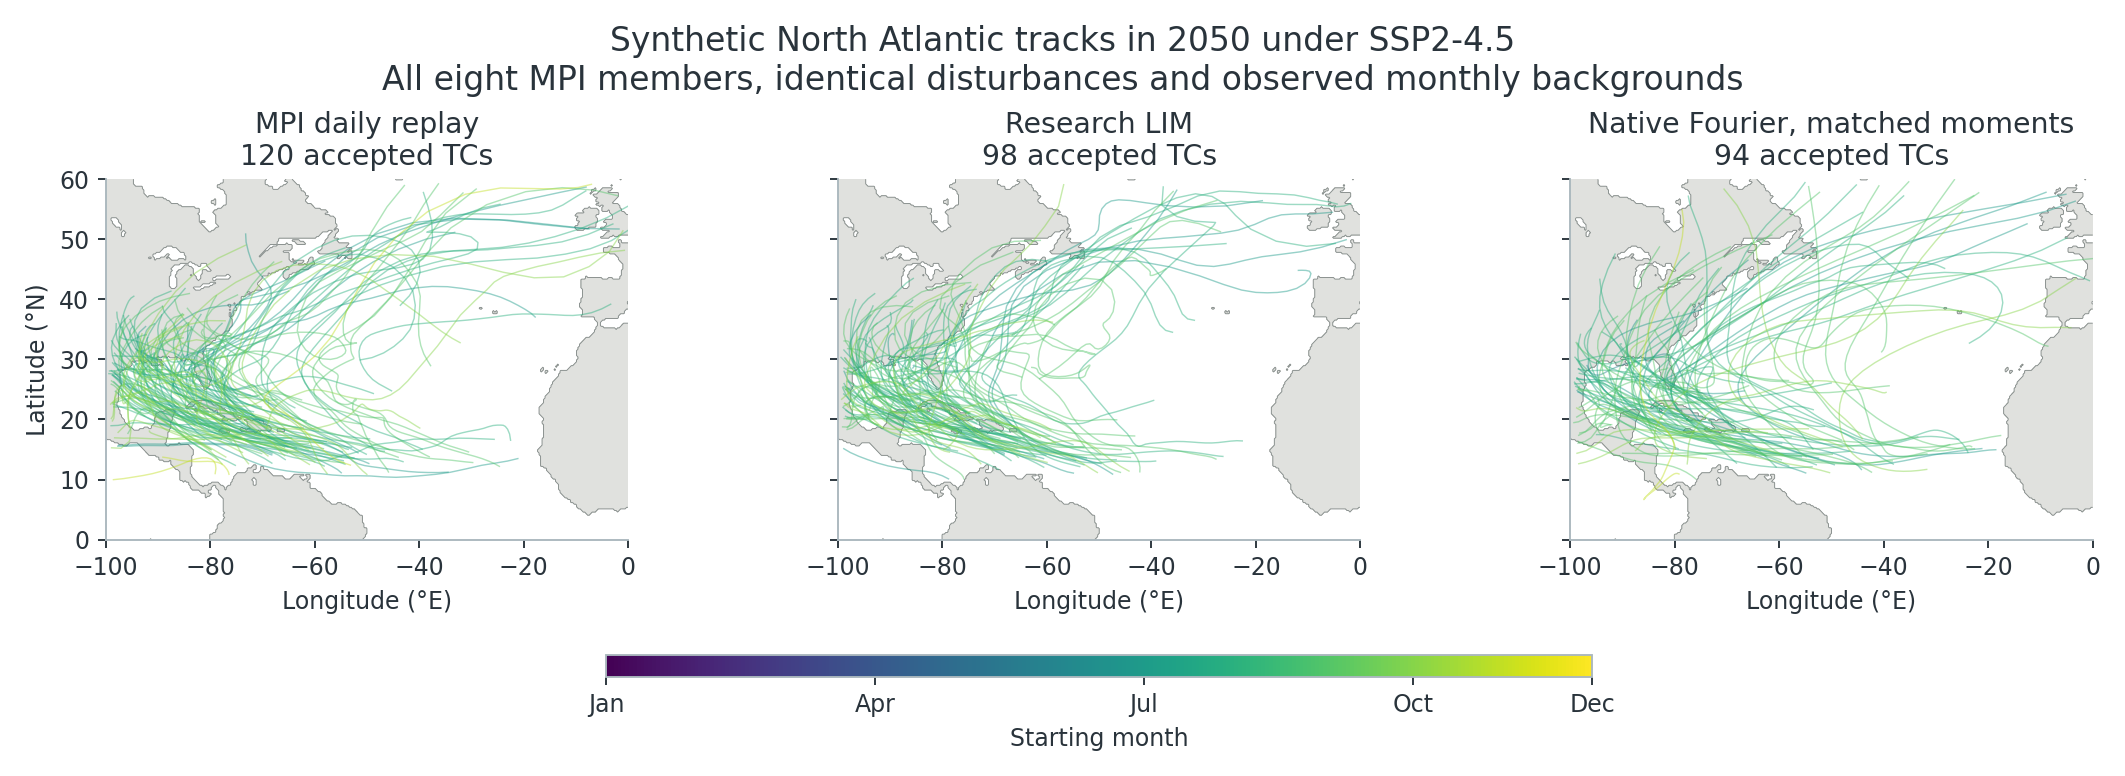

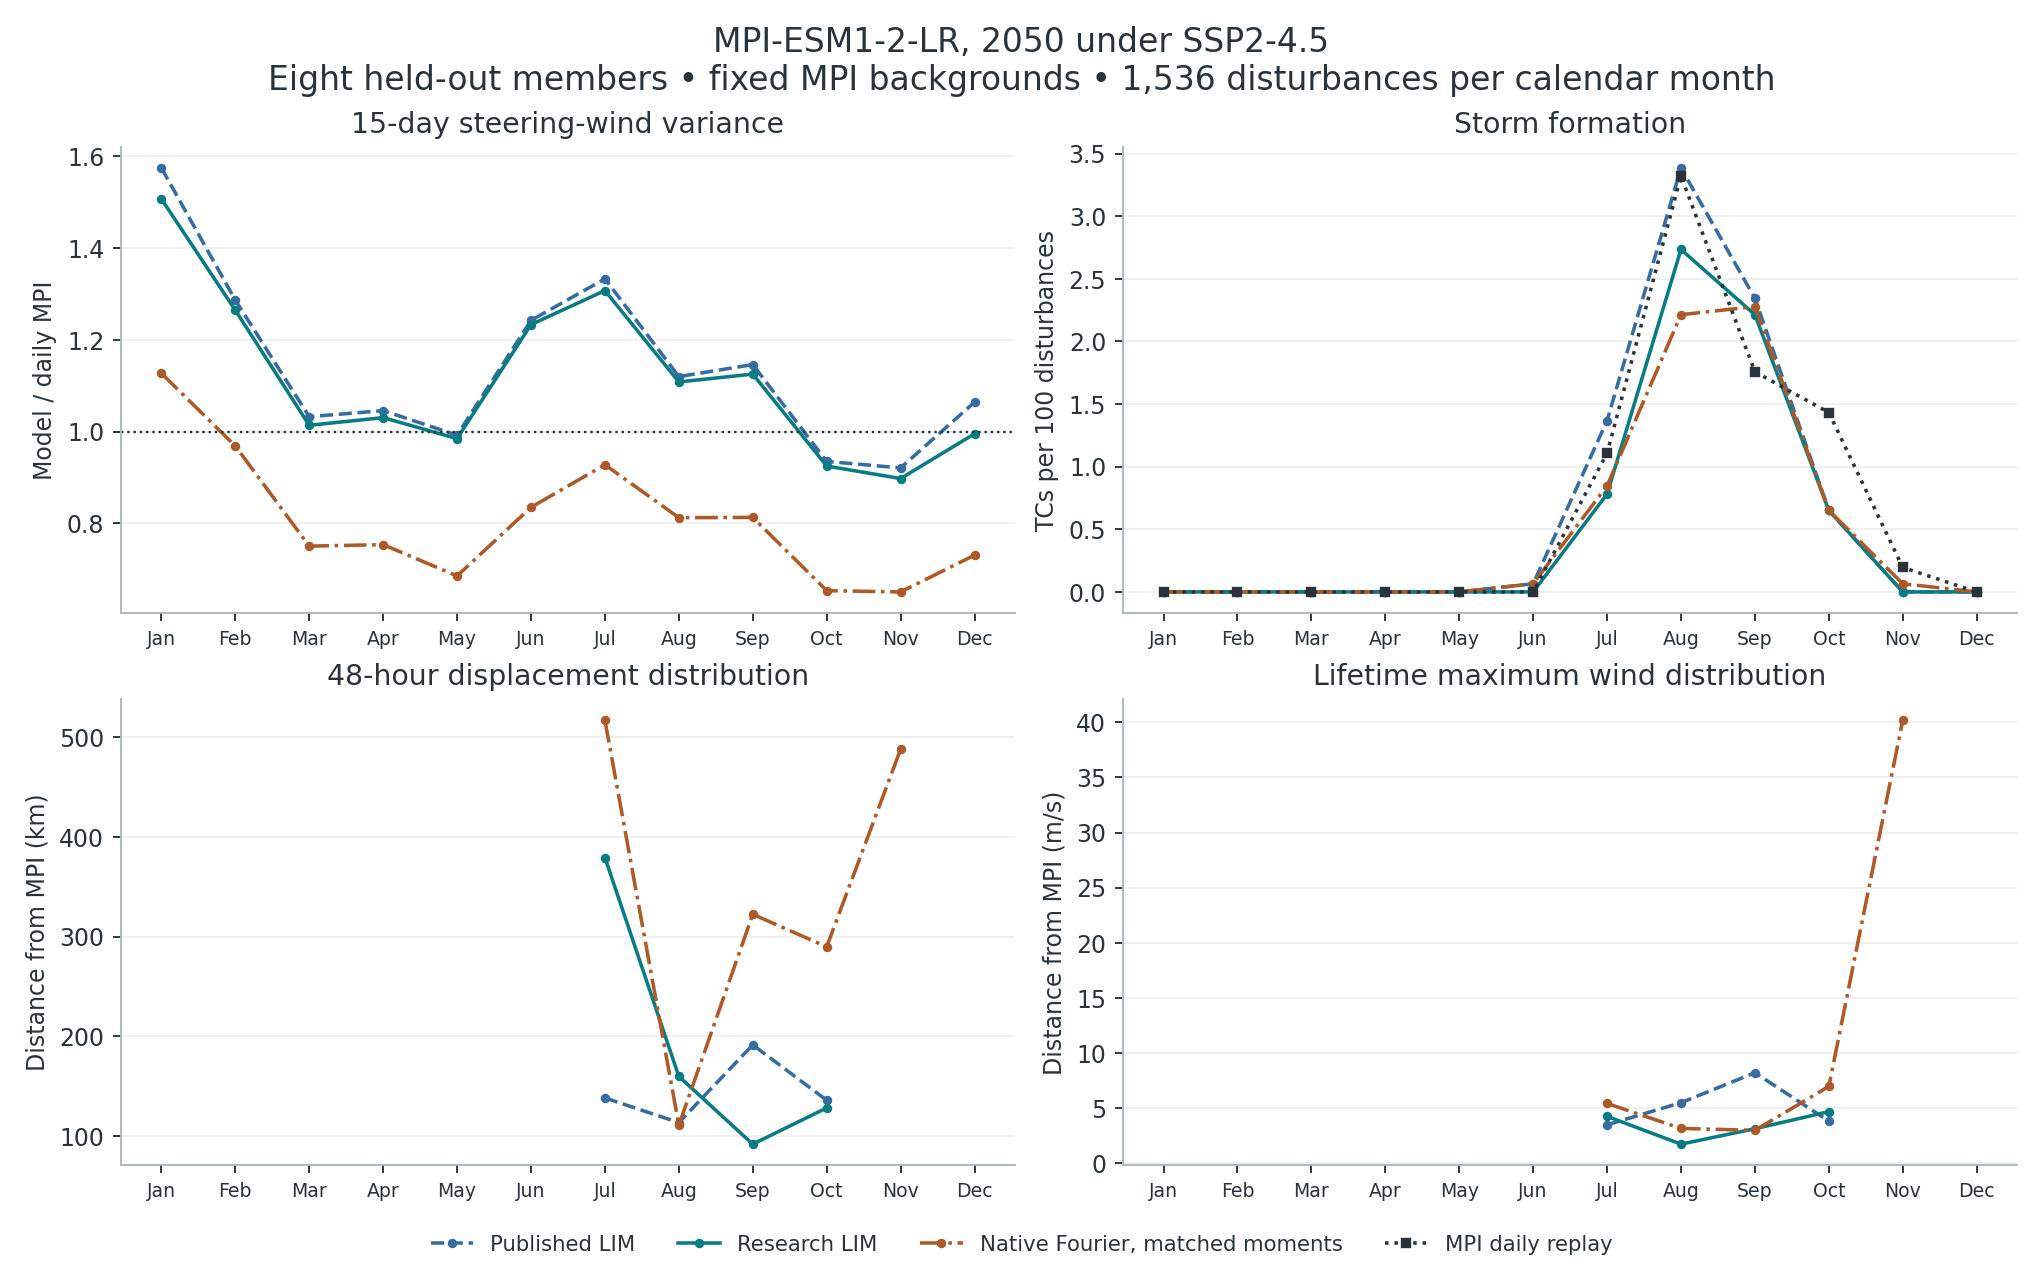

In [17]:
import json
from IPython.display import Image, display

study = root / "reports" / "annual_refinement"
selected = json.loads((study / "freeze_receipt.json").read_text())["stage"]
annual = pd.read_csv(study / "data" / "annual_mpi2050_storms.csv", dtype={"month": str})
panel = annual[(annual.month == "all") & (annual.protocol == "MPI background")]
drivers = {
    "published_v1": "Published LIM",
    selected: "Research LIM",
    "native_fourier": "Native Fourier, published moments",
    "selected_fourier": "Native Fourier, research moments",
}
rows = []
for driver, label in drivers.items():
    scores = panel[panel.driver == driver].set_index("metric")
    formation = scores.loc["tc"]
    if not rows:
        rows.append(["MPI daily replay", int(formation.ref_tc), formation.reference, 0., 0.])
    rows.append([label, int(formation.tc), formation.value,
                 scores.loc["displacement_48h_km", "error"], scores.loc["lmi", "error"]])
table = pd.DataFrame(rows, columns=["Driver", "TCs", "TCs per 100 seeds", "48-hour distance W1 (km)", "Lifetime wind W1 (m/s)"])
attempts = pd.read_parquet(study / "data" / "annual_mpi2050_attempts.parquet", columns=["model", "protocol", "tc"])
reference = attempts[(attempts.model == "mpi_daily") & (attempts.protocol == "MPI daily")]
assert len(reference) == 8 * 12 * 2 * 96
assert int(reference.tc.sum()) == rows[0][1]
display(table.set_index("Driver").round(2))
display(Image(filename=str(study / "figures" / "ssp245_annual_tracks.png"), width=940))
display(Image(filename=str(study / "figures" / "ssp245_calendar.png"), width=940))

The map shows every accepted storm under each of three drivers, with color indicating the starting month. The monthly lines show where formation and track statistics change with season. A gap in a distributional comparison indicates that at least one driver produced no storms with the required measurement. The annual replay covers one scenario year, so its uncertainty intervals measure differences among these MPI members. The research report includes six-hourly September tracks, alternative weather controls and paired intervals. [Annual and September MPI benchmarks](../reports/annual_refinement/README.md)